In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'C:\Data Analyst\Python\retail-sales-weather-analysis\data\data.csv')


Проверяем формат столбцов

In [3]:
print(df.dtypes)

Дата            object
Склад            int64
Контрагент      object
Номенклатура    object
Количество       int64
dtype: object


Сразу переведем столбец "Дата" в правильный формат

In [4]:
df['Дата'] = pd.to_datetime(df['Дата'], errors='coerce')


In [5]:
print(df.dtypes)  
print(df.head()) 

Дата            datetime64[ns]
Склад                    int64
Контрагент              object
Номенклатура            object
Количество               int64
dtype: object
        Дата  Склад Контрагент Номенклатура  Количество
0 2018-01-04      1  address_0    product_0           4
1 2018-01-04      1  address_0    product_1           4
2 2018-01-04      1  address_0    product_2           5
3 2018-01-04      1  address_0    product_3          10
4 2018-01-04      1  address_0    product_4           2


Сгруппируйте данные по дате, посчитайте количество продаж

In [6]:
grouped_df = df.groupby('Дата')['Количество'].sum().reset_index()

Вывести несколько первых строк сгруппированных данных

In [7]:
print(grouped_df.head())


        Дата  Количество
0 2018-01-04        3734
1 2018-01-05        3643
2 2018-01-06        3193
3 2018-01-07        3298
4 2018-01-09        4055


Нарисуйте график продаж у `grouped_df`

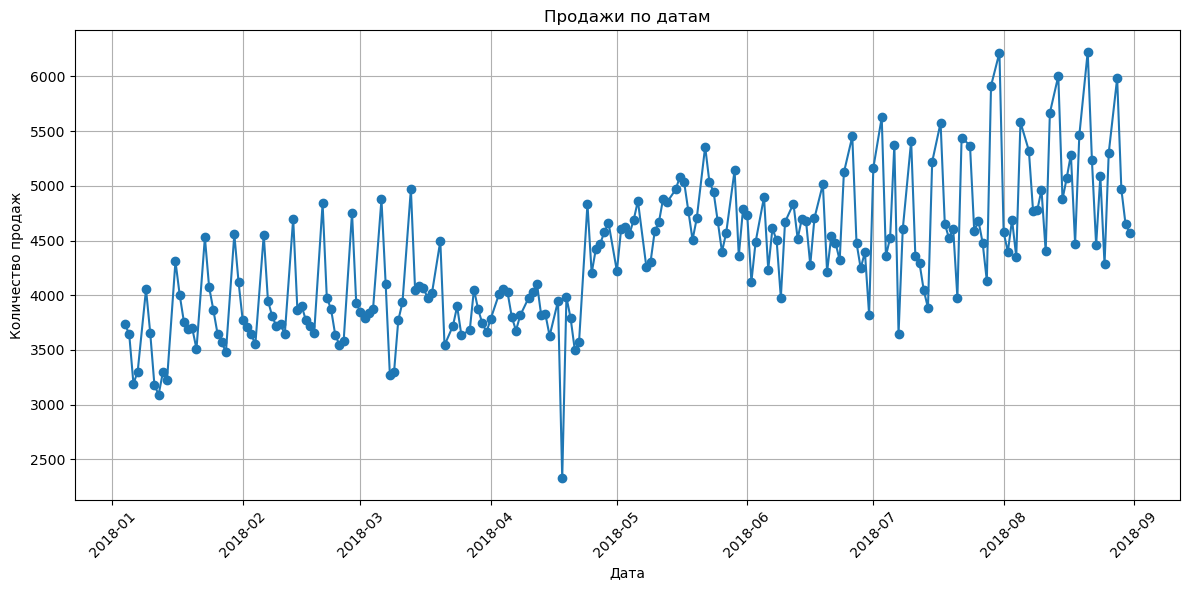

In [8]:
plt.figure(figsize=(12, 6))
plt.plot(grouped_df['Дата'], grouped_df['Количество'], marker='o')


plt.title('Продажи по датам')
plt.xlabel('Дата')
plt.ylabel('Количество продаж')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


Опишите что вы видите на графике. Ваша задача - максимально описать график

Продажи растут с января по сентябрь 2018 года. Начиная с мая виден особенно заметный рост. Есть регулярные колебания — вероятно, недельные. 
В начале апреля — резкий спад, возможно, из-за праздников. Летом значения достигают пика.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [9]:
Q1 = df['Количество'].quantile(0.25)
Q3 = df['Количество'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


In [10]:
outliers = df[(df['Количество'] < lower_bound) | (df['Количество'] > upper_bound)]


In [11]:
max_outlier = outliers.sort_values(by='Количество', ascending=False).head(1)
print(max_outlier)


             Дата  Склад   Контрагент Номенклатура  Количество
218822 2018-06-28      1  address_208    product_0         200


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [12]:
summer_wednesdays = df[
    (df['Дата'].dt.month.isin([6, 7, 8])) & 
    (df['Дата'].dt.dayofweek == 2) &  # 0=Пн, 1=Вт, 2=Ср, ...
    (df['Склад'] == 3)
]

# Группируем по товарам и считаем сумму продаж
top_product = summer_wednesdays.groupby('Номенклатура')['Количество'].sum().sort_values(ascending=False)

# Выводим топ-1
print("Топовый товар по продажам по средам (летом) на складе 3:")
print(top_product.head(1))

Топовый товар по продажам по средам (летом) на складе 3:
Номенклатура
product_1    2267
Name: Количество, dtype: int64


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [15]:
weather = pd.read_csv(r'C:\Data Analyst\Python\retail-sales-weather-analysis\data\weather.csv',
                      sep=';', comment='#', index_col=False)

In [16]:
# Первый столбец - дата и время наблюдения, T - температура
weather['date'] = pd.to_datetime(weather.iloc[:, 0], dayfirst=True).dt.normalize()
df_daily_temp = weather.groupby('date')['T'].mean().reset_index()
print(df_daily_temp.head())

        date        T
0 2018-01-01  -9.4625
1 2018-01-02  -9.5125
2 2018-01-03 -11.4625
3 2018-01-04 -14.0750
4 2018-01-05 -16.8625


In [17]:
merged_df = pd.merge(grouped_df, df_daily_temp, left_on='Дата', right_on='date', how='inner')
print(merged_df.head())

        Дата  Количество       date        T
0 2018-01-04        3734 2018-01-04 -14.0750
1 2018-01-05        3643 2018-01-05 -16.8625
2 2018-01-06        3193 2018-01-06 -13.3000
3 2018-01-07        3298 2018-01-07 -12.7500
4 2018-01-09        4055 2018-01-09  -6.2500


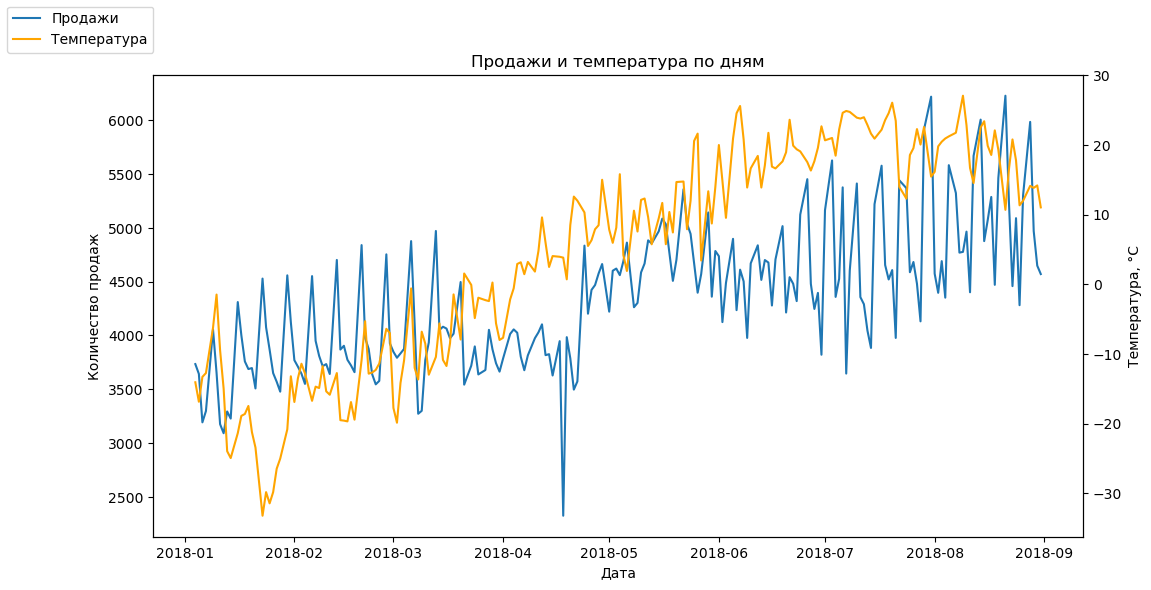

Корреляция продаж и температуры: 0.6


In [25]:
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(merged_df['Дата'], merged_df['Количество'], label='Продажи')
ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество продаж')

ax2 = ax1.twinx()
ax2.plot(merged_df['Дата'], merged_df['T'], color='orange', label='Температура')
ax2.set_ylabel('Температура, °C')

fig.legend(loc='upper left')
plt.title('Продажи и температура по дням')
plt.title('Продажи и температура по дням')
plt.savefig(r'C:\Data Analyst\Python\retail-sales-weather-analysis\images\sales_vs_temperature.png', dpi=120, bbox_inches='tight')
plt.show()

print('Корреляция продаж и температуры:', round(merged_df['Количество'].corr(merged_df['T']), 2))

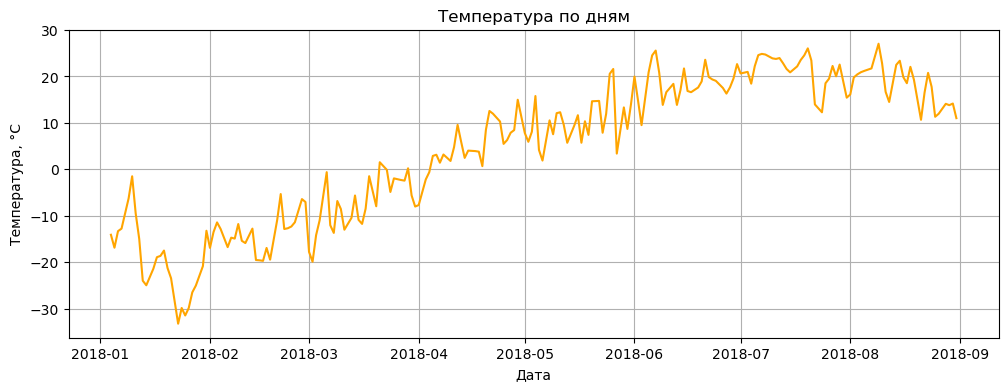

In [19]:
plt.figure(figsize=(12, 4))
plt.plot(merged_df['Дата'], merged_df['T'], color='orange')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.title('Температура по дням')
plt.grid(True)
plt.show()

Вывод: продажи и средняя дневная температура имеют умеренную положительную корреляцию (r = 0.6). При этом обе величины растут с января по август, поэтому часть связи, вероятно, объясняется общим сезонным трендом, а не прямым влиянием температуры на продажи.
